## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import StackingClassifier, AdaBoostClassifier, VotingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

import sklearn
print("Scikit-learn version:", sklearn.__version__)

Scikit-learn version: 1.8.0


## 2. Load and Explore the Dataset

In [2]:
digits = load_digits()
X = digits.data
y = digits.target

print("Dataset shape:", X.shape)
print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])
print("Classes:", np.unique(y))
print("Missing values:", np.isnan(X).sum())

Dataset shape: (1797, 64)
Number of samples: 1797
Number of features: 64
Classes: [0 1 2 3 4 5 6 7 8 9]
Missing values: 0


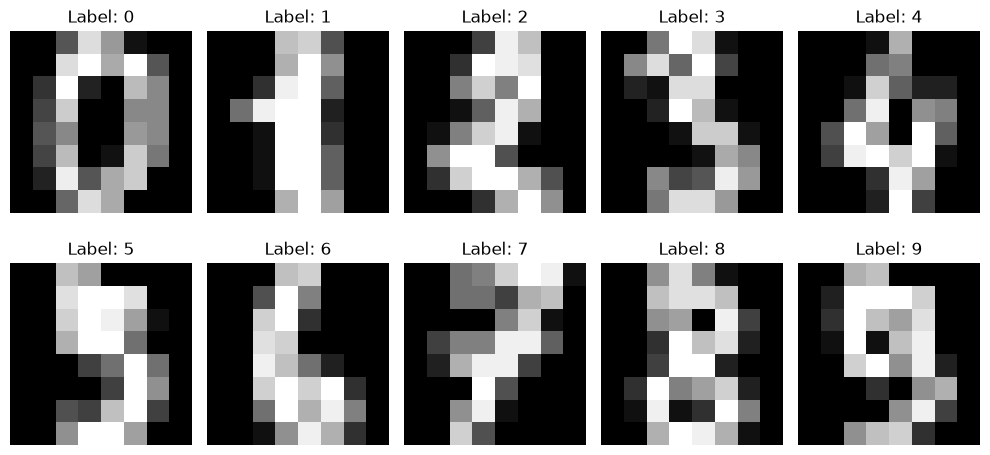

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for ax, image, label in zip(axes.ravel(), digits.images[:10], digits.target[:10]):
    ax.imshow(image, cmap="gray")
    ax.set_title(f"Label: {label}")
    ax.axis("off")
plt.tight_layout()
plt.show()

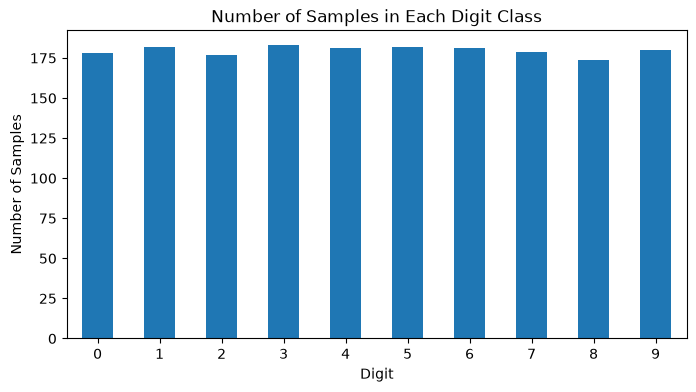

In [4]:
pd.Series(y).value_counts().sort_index().plot(kind="bar", figsize=(8, 4))
plt.title("Number of Samples in Each Digit Class")
plt.xlabel("Digit")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.show()

## 3. Split the Dataset
A stratified split maintains approximately the same class distribution in the training and testing sets.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1437
Testing samples: 360


## 4. Define Base Classifiers

Four base classifiers are used: Logistic Regression, Decision Tree, K-Nearest Neighbors (KNN), and Support Vector Machine (SVM). StandardScaler is included in pipelines for scale-sensitive classifiers. Scaling is fitted only on training data.

In [6]:
base_models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=3000, random_state=42))
    ]),
    "Decision Tree": DecisionTreeClassifier(max_depth=10, random_state=42),
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=5))
    ]),
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(kernel="rbf", probability=True, random_state=42))
    ])
}

for name, model in base_models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully")

Logistic Regression trained successfully
Decision Tree trained successfully
KNN trained successfully
SVM trained successfully


## 5. Stacking Ensemble
Stacking combines predictions from multiple base classifiers. Logistic Regression is used as the meta-classifier. Five-fold cross-validation generates predictions for training the meta-classifier.

In [7]:
stacking_model = StackingClassifier(
    estimators=[
        ("lr", base_models["Logistic Regression"]),
        ("dt", base_models["Decision Tree"]),
        ("knn", base_models["KNN"]),
        ("svm", base_models["SVM"])
    ],
    final_estimator=LogisticRegression(max_iter=3000, random_state=42),
    cv=5,
    stack_method="predict_proba",
    n_jobs=-1
)
stacking_model.fit(X_train, y_train)
print("Stacking ensemble trained successfully")

Stacking ensemble trained successfully


## 6. AdaBoost Ensemble
AdaBoost trains weak learners sequentially, giving greater attention to samples misclassified by earlier learners. A decision stump (Decision Tree with depth 1) is used as the weak learner.

In [8]:
ada_base_learner = DecisionTreeClassifier(max_depth=1, random_state=42)

adaboost_model = AdaBoostClassifier(
    estimator=ada_base_learner,
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)
adaboost_model.fit(X_train, y_train)
print("AdaBoost ensemble trained successfully")

AdaBoost ensemble trained successfully


## 7. Voting Ensemble
Hard voting is used. Each classifier votes for one class, and the class receiving the highest number of votes becomes the final prediction.

In [9]:
voting_model = VotingClassifier(
    estimators=[
        ("lr", base_models["Logistic Regression"]),
        ("dt", base_models["Decision Tree"]),
        ("knn", base_models["KNN"]),
        ("svm", base_models["SVM"])
    ],
    voting="hard",
    n_jobs=-1
)
voting_model.fit(X_train, y_train)
print("Voting ensemble trained successfully")

Voting ensemble trained successfully


## 8. Evaluate Base and Ensemble Models
Macro precision, recall, and F1-score calculate each metric separately for every digit class and then give all 10 classes equal weight.

In [10]:
all_models = {
    **base_models,
    "Stacking": stacking_model,
    "AdaBoost": adaboost_model,
    "Voting": voting_model
}

results = []
predictions = {}

for name, model in all_models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (Macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall (Macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1-Score (Macro)": f1_score(y_test, y_pred, average="macro", zero_division=0)
    })

results_df = pd.DataFrame(results).sort_values(
    by="F1-Score (Macro)", ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro)
0,Stacking,0.9861,0.9862,0.9860,0.9860
1,SVM,0.9750,0.9760,0.9748,0.9748
2,Logistic Regression,0.9722,0.9721,0.9719,0.9719
3,Voting,0.9667,0.9677,0.9663,0.9661
4,KNN,0.9639,0.9646,0.9637,0.9634
5,AdaBoost,0.8250,0.8331,0.8245,0.8258
6,Decision Tree,0.8111,0.8145,0.8104,0.8114


## 9. Classification Reports
The report shows precision, recall, F1-score, and support for each digit class.

In [11]:
for name, y_pred in predictions.items():
    print("\\n" + "=" * 65)
    print(name)
    print("=" * 65)
    print(classification_report(y_test, y_pred, zero_division=0))

\n=================================================================
Logistic Regression
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.89      0.89      0.89        36
           2       1.00      1.00      1.00        35
           3       0.97      1.00      0.99        37
           4       0.97      1.00      0.99        36
           5       1.00      1.00      1.00        37
           6       1.00      0.97      0.99        36
           7       1.00      1.00      1.00        36
           8       0.89      0.89      0.89        35
           9       1.00      0.97      0.99        36

    accuracy                           0.97       360
   macro avg       0.97      0.97      0.97       360
weighted avg       0.97      0.97      0.97       360

\n=================================================================
Decision Tree
              precision    recall  f1-score   support

           0    

## 10. Confusion Matrices for All Models
Diagonal cells show correct predictions. Off-diagonal cells show misclassifications.

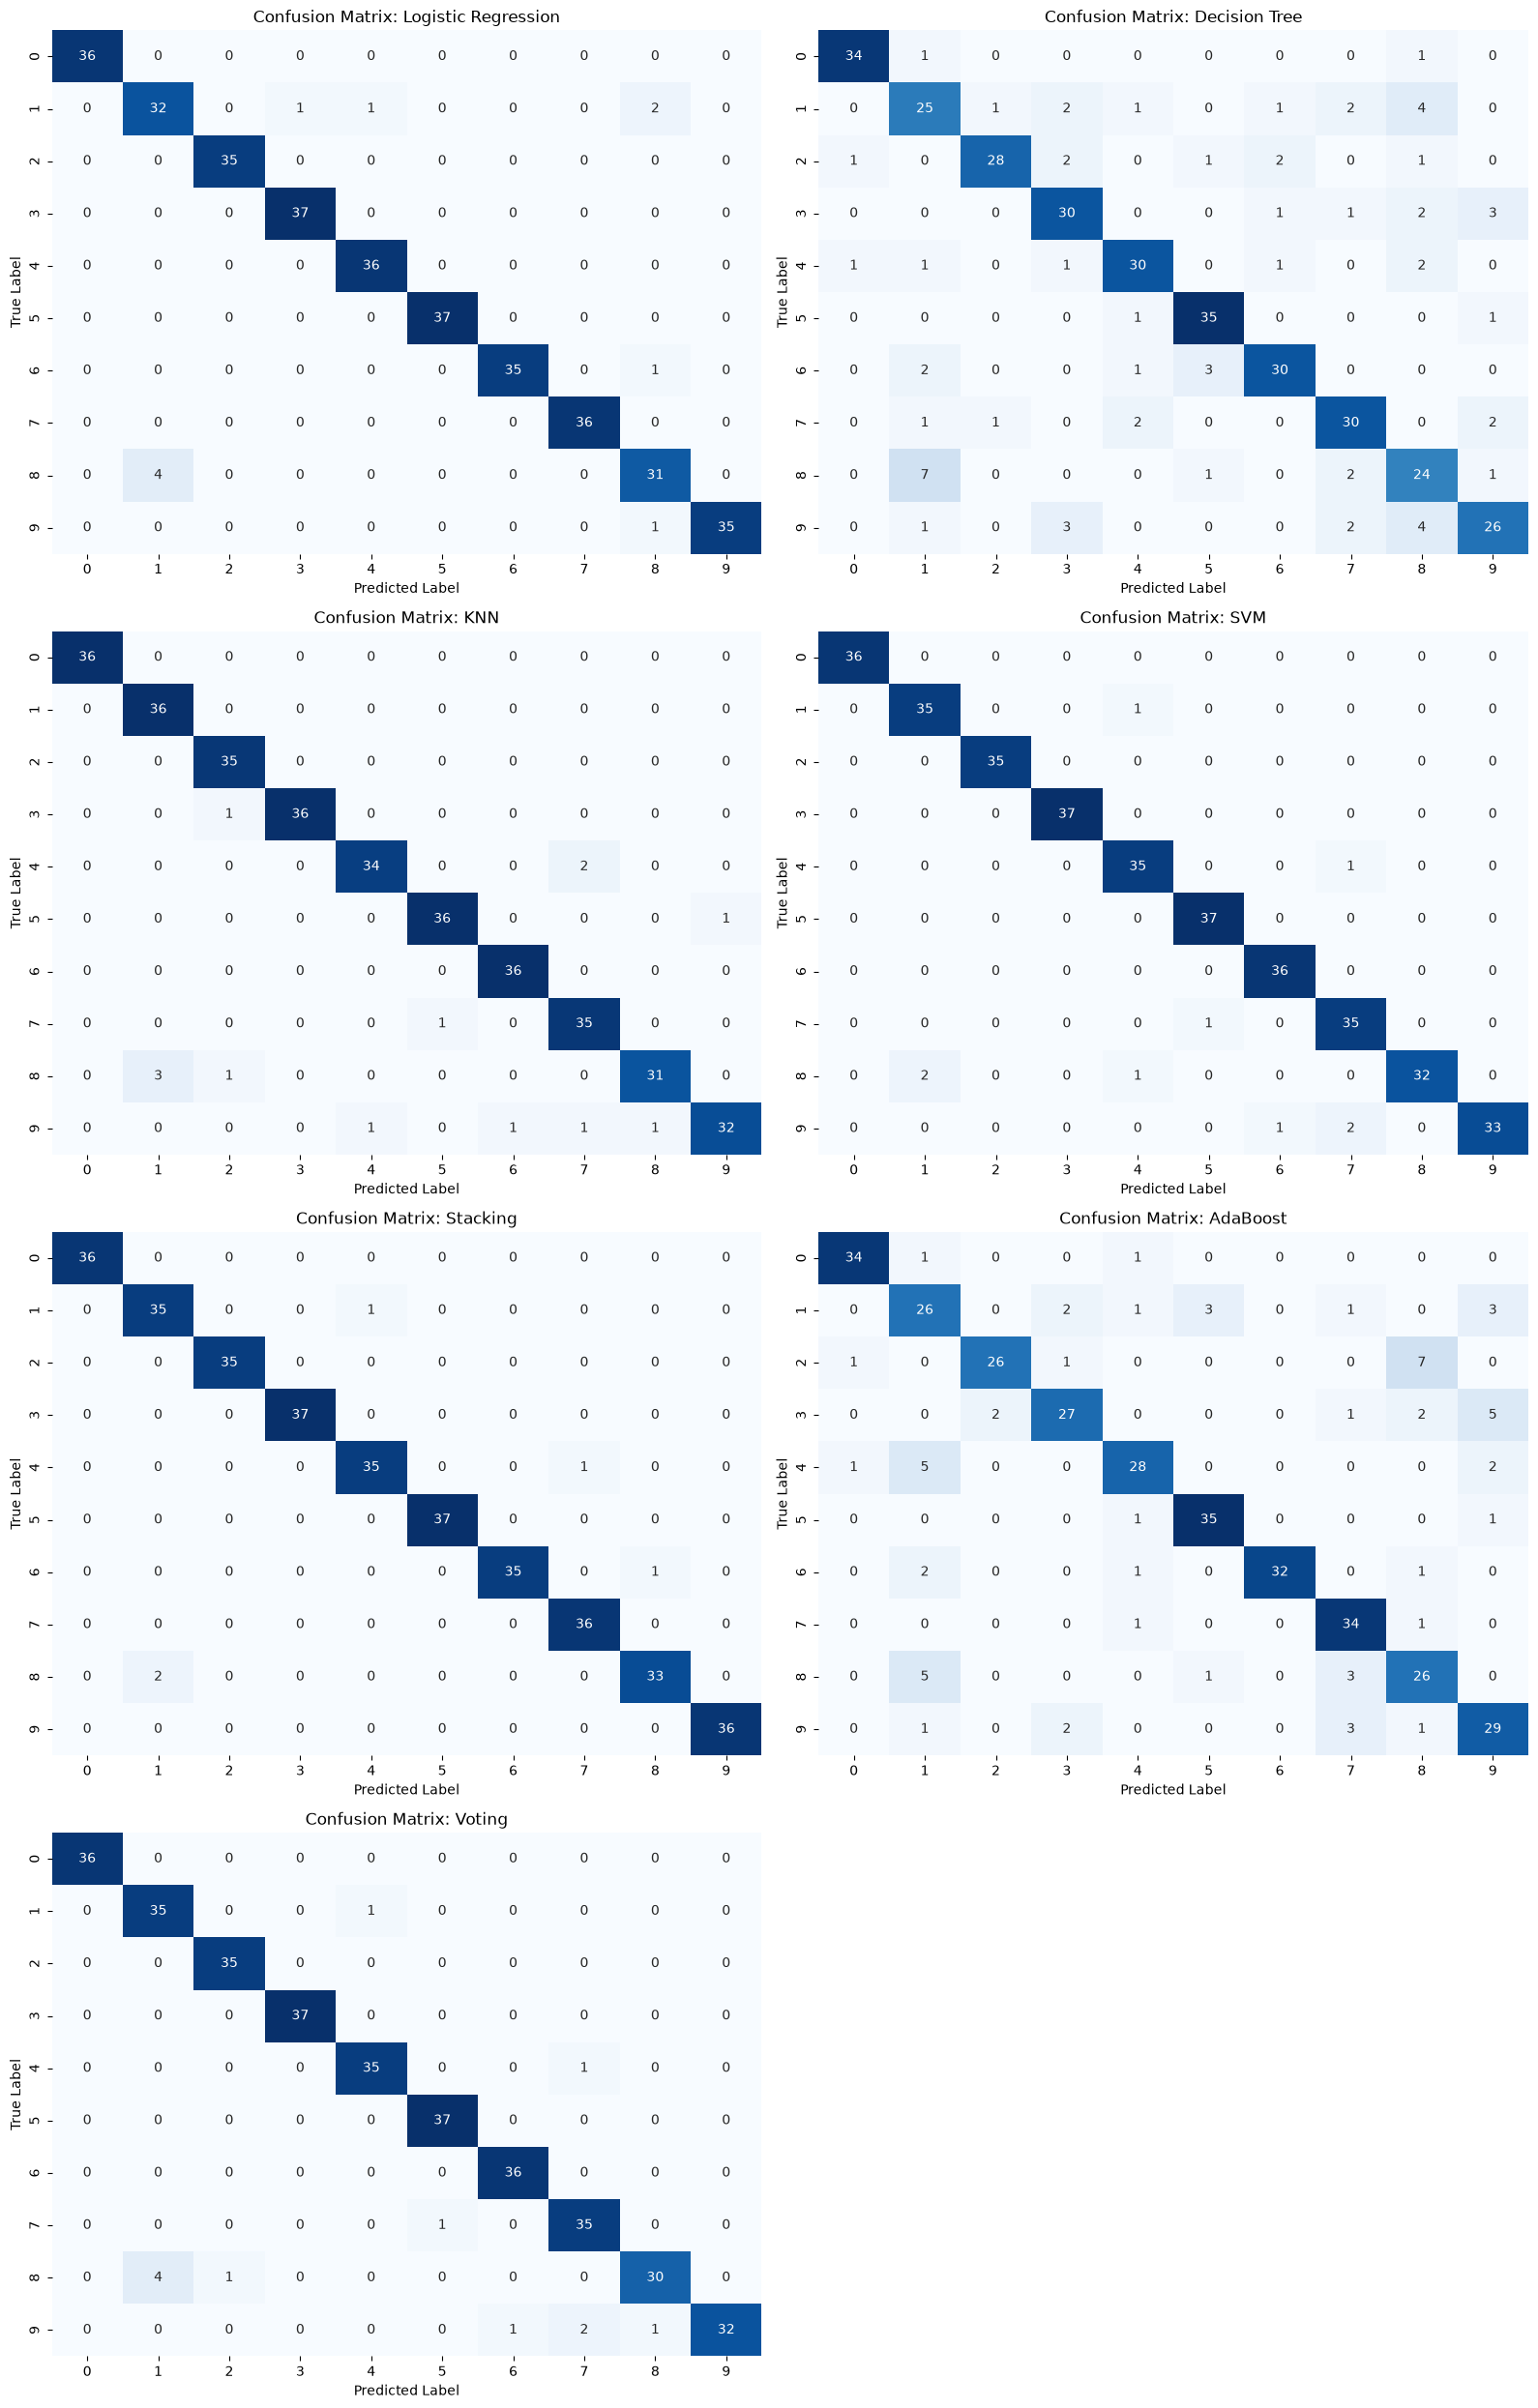

In [12]:
fig, axes = plt.subplots(4, 2, figsize=(16, 25))
axes = axes.ravel()

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=np.arange(10))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=np.arange(10), yticklabels=np.arange(10), ax=ax
    )
    ax.set_title(f"Confusion Matrix: {name}")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")

axes[-1].axis("off")
plt.tight_layout()
plt.show()

## 11. Compare Model Performance Using Charts

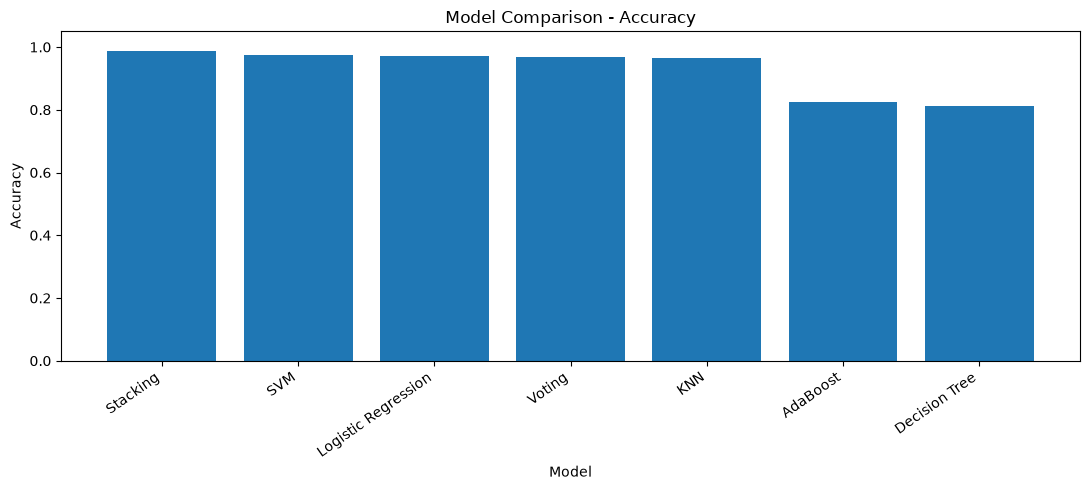

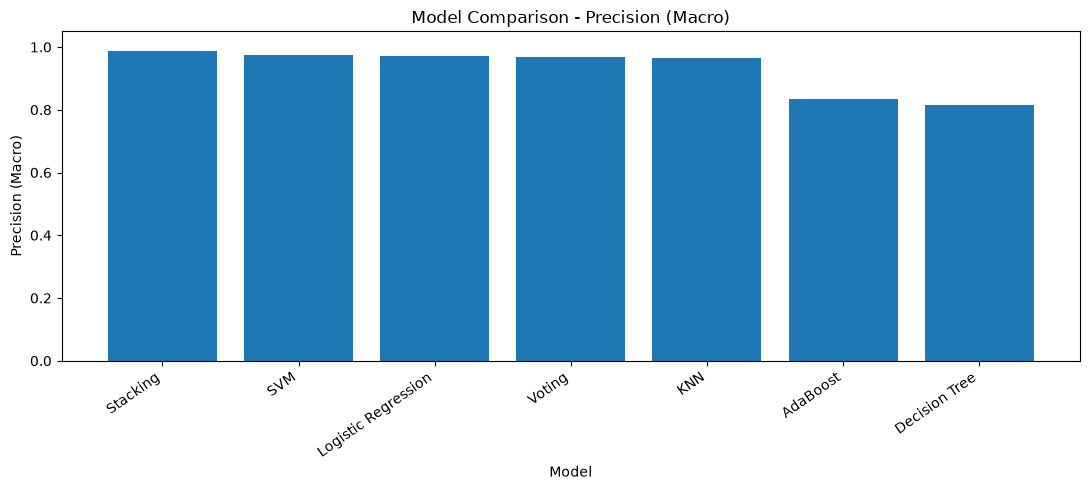

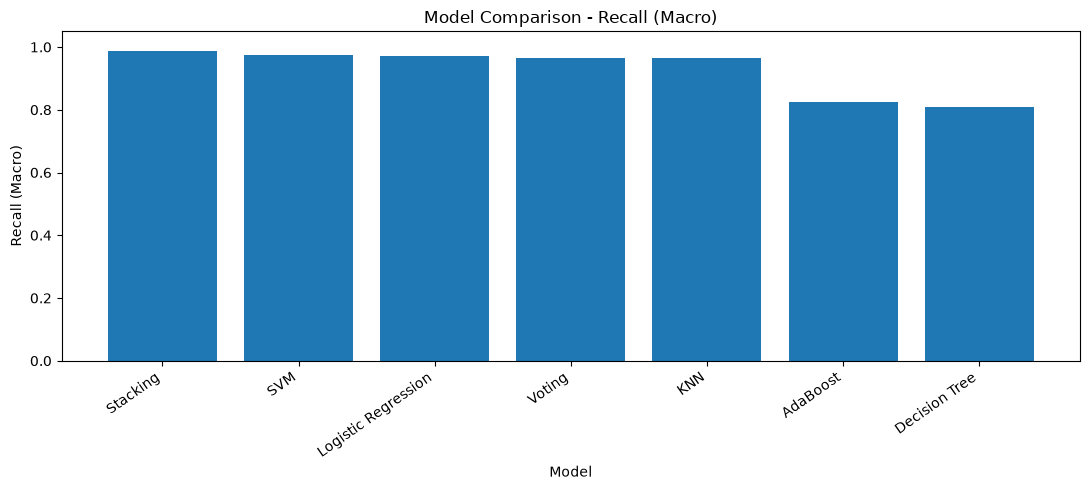

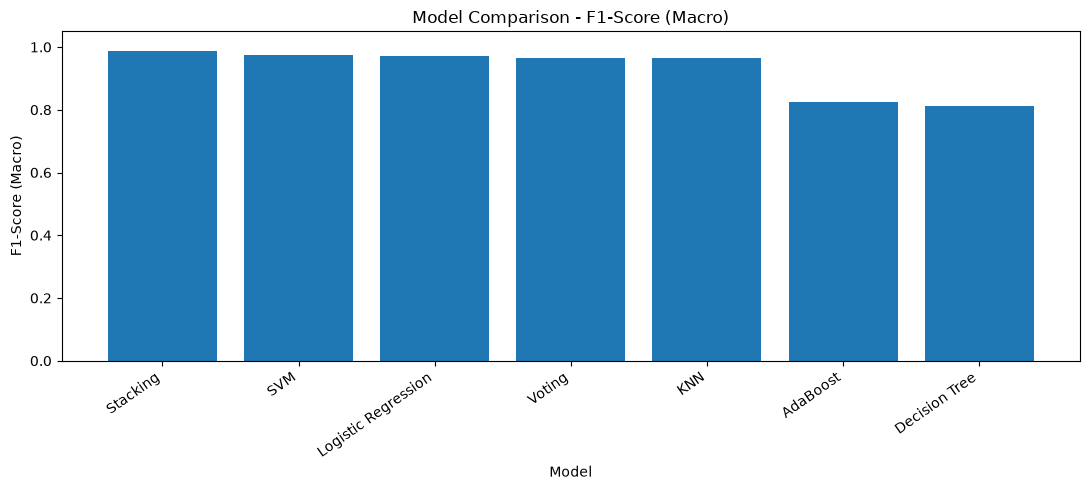

In [ ]:
for metric in ["Accuracy", "Precision ", "Recall ", "F1-Score "]:
    plt.figure(figsize=(11, 5))
    plt.bar(results_df["Model"], results_df[metric])
    plt.title(f"Model Comparison - {metric}")
    plt.xlabel("Model")
    plt.ylabel(metric)
    plt.ylim(0, 1.05)
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

## 13. Identify the Best Model

In [15]:
best_model_row = results_df.iloc[0]
print("Best model based on Macro F1-Score:", best_model_row["Model"])
print("Accuracy:", round(best_model_row["Accuracy"], 4))
print("Macro Precision:", round(best_model_row["Precision (Macro)"], 4))
print("Macro Recall:", round(best_model_row["Recall (Macro)"], 4))
print("Macro F1-Score:", round(best_model_row["F1-Score (Macro)"], 4))

Best model based on Macro F1-Score: Stacking
Accuracy: 0.9861
Macro Precision: 0.9862
Macro Recall: 0.986
Macro F1-Score: 0.986
